<a href="https://colab.research.google.com/github/Sanathcharan/bike-sharing-rentals/blob/main/bike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

## 1.EDA

In [ ]:
df=pd.read_csv('Dataset.csv')
df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,31-12-2012,springer,2012,12,19,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,11,108,119
17375,17376,31-12-2012,springer,2012,12,20,No,1,Working Day,Mist,0.26,0.2576,0.6,0.1642,8,81,89
17376,17377,31-12-2012,springer,2012,12,21,No,1,Working Day,Clear,?,0.2576,0.6,0.1642,7,83,90
17377,17378,31-12-2012,springer,2012,12,22,No,1,Working Day,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [ ]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


In [ ]:
#Dropping Unwanted Columns
df.drop(columns='instant',inplace=True)

In [ ]:
df.shape

(17379, 16)

In [ ]:
df.size

278064

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   dteday      17379 non-null  object
 1   season      17379 non-null  object
 2   yr          17379 non-null  object
 3   mnth        17379 non-null  object
 4   hr          17379 non-null  int64 
 5   holiday     17379 non-null  object
 6   weekday     17379 non-null  int64 
 7   workingday  17379 non-null  object
 8   weathersit  17379 non-null  object
 9   temp        17379 non-null  object
 10  atemp       17379 non-null  object
 11  hum         17379 non-null  object
 12  windspeed   17379 non-null  object
 13  casual      17379 non-null  object
 14  registered  17379 non-null  object
 15  cnt         17379 non-null  int64 
dtypes: int64(3), object(13)
memory usage: 2.1+ MB


In [ ]:
df.dtypes

,0
dteday,object
season,object
yr,object
mnth,object
hr,int64
holiday,object
weekday,int64
workingday,object
weathersit,object
temp,object


In [ ]:
df.columns

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [ ]:
(df.astype(str) == "?").sum()

,0
dteday,0
season,6
yr,1
mnth,1
hr,0
holiday,1
weekday,0
workingday,5
weathersit,4
temp,11


In [ ]:
df.replace("?", np.nan, inplace=True)

In [ ]:
df.isnull().sum()

,0
dteday,0
season,6
yr,1
mnth,1
hr,0
holiday,1
weekday,0
workingday,5
weathersit,4
temp,11


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count / len(df)) * 100
missing_table = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})
missing_table = missing_table[missing_table["Missing Values"] > 0]
display(missing_table.round(2))

,Missing Values,Missing Percentage (%)
season,6,0.03
yr,1,0.01
mnth,1,0.01
holiday,1,0.01
workingday,5,0.03
weathersit,4,0.02
temp,11,0.06
atemp,6,0.03
hum,6,0.03
windspeed,5,0.03


In [ ]:
# Fill categorical columns with their most frequent value
categorical_columns = ["season", "holiday", "workingday", "weathersit"]
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Fill numerical columns with their median
numeric_columns = ["yr", "mnth", "temp", "atemp", "hum","windspeed", "casual", "registered"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].median())
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Total missing values: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  object 
 1   season      17379 non-null  object 
 2   yr          17379 non-null  float64
 3   mnth        17379 non-null  float64
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  object 
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  object 
 8   weathersit  17379 non-null  object 
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  casual      17379 non-null  float64
 14  registered  17379 non-null  float64
 15  cnt         17379 non-null  int64  
dtypes: float64(8), int64(3), object(5)
memory usage: 2.1+ MB


In [ ]:
df.shape

(17379, 16)

In [ ]:
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,01-01-2011,springer,2011.0,1.0,0,No,6,No work,Clear,0.24,0.2879,0.81,0.0,3.0,13.0,16
1,01-01-2011,springer,2011.0,1.0,1,No,6,No work,Clear,0.22,0.2727,0.80,0.0,8.0,32.0,40
2,01-01-2011,springer,2011.0,1.0,2,No,6,No work,Clear,0.22,0.2727,0.63,0.0,5.0,27.0,32
3,01-01-2011,springer,2011.0,1.0,3,No,6,No work,Clear,0.24,0.2879,0.75,0.0,3.0,10.0,13
4,01-01-2011,springer,2011.0,1.0,4,No,6,No work,Clear,0.24,0.2879,0.75,0.0,0.0,1.0,1


In [ ]:
numerical_columns = df.select_dtypes(include=np.number).columns

# Detect potential outliers using IQR
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ).sum()

    print(f"{col}: {outlier_count} potential outliers")

yr: 0 potential outliers
mnth: 0 potential outliers
hr: 0 potential outliers
weekday: 0 potential outliers
temp: 0 potential outliers
atemp: 0 potential outliers
hum: 22 potential outliers
windspeed: 341 potential outliers
casual: 1192 potential outliers
registered: 680 potential outliers
cnt: 505 potential outliers


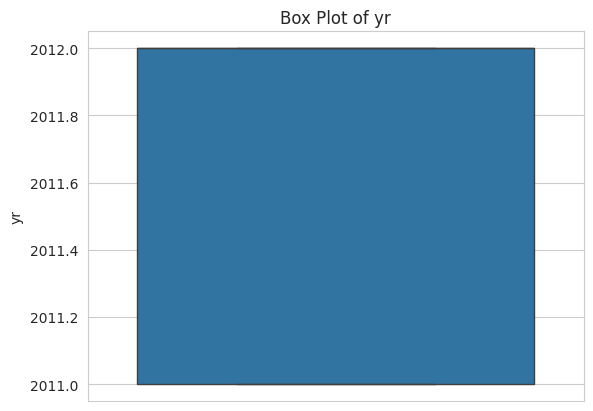

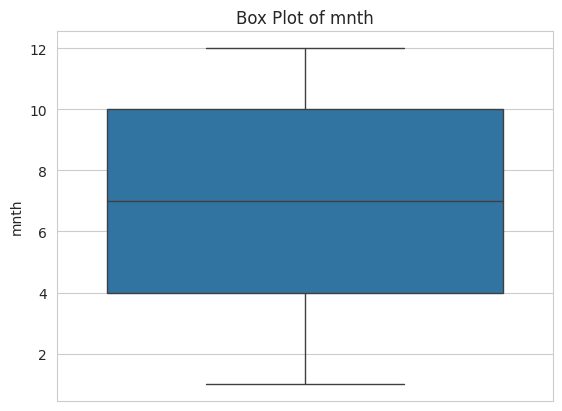

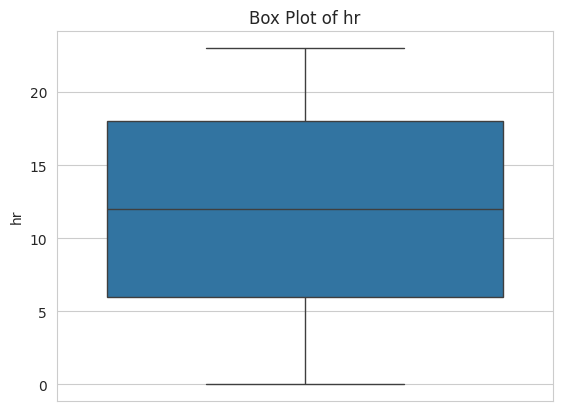

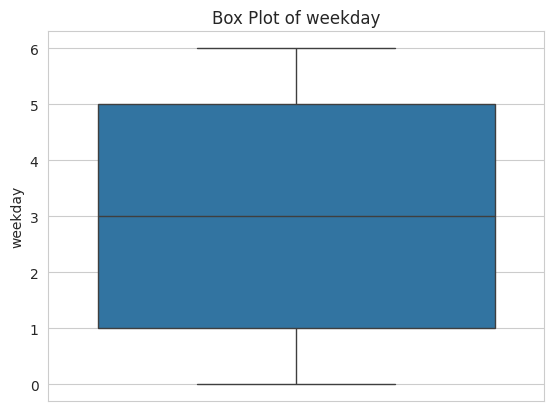

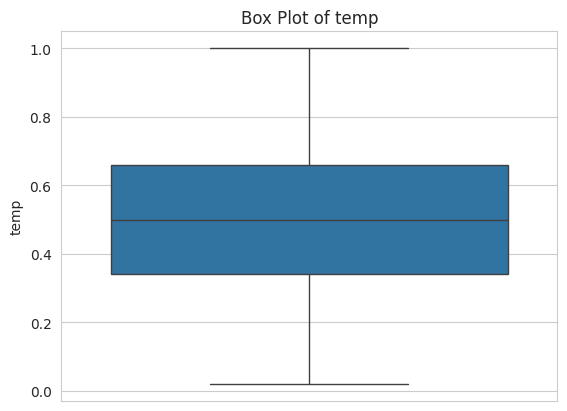

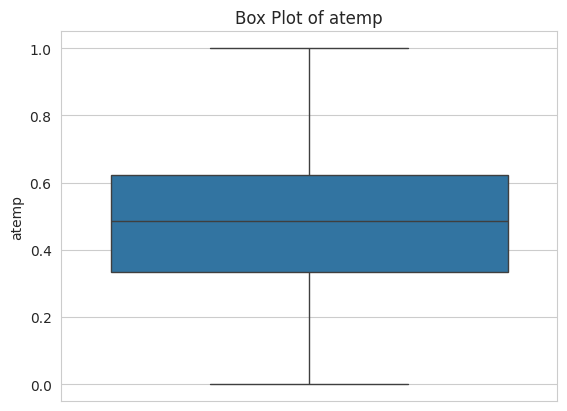

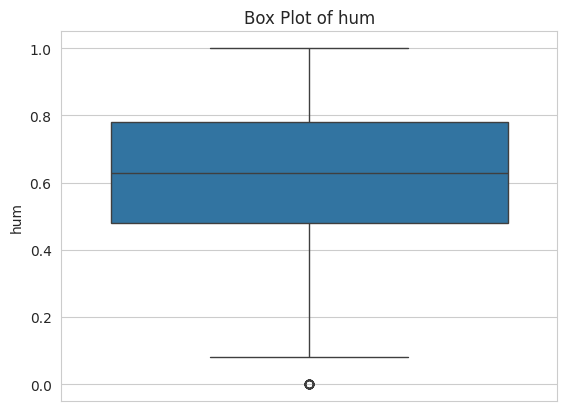

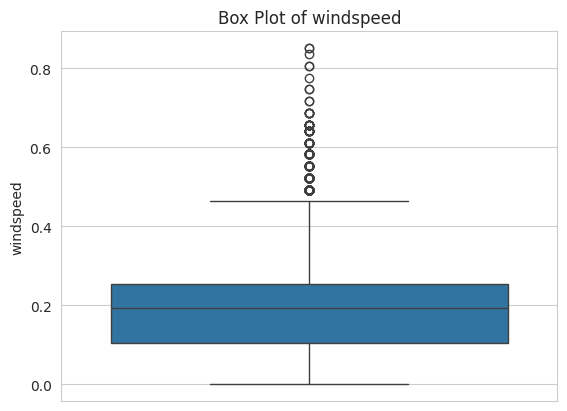

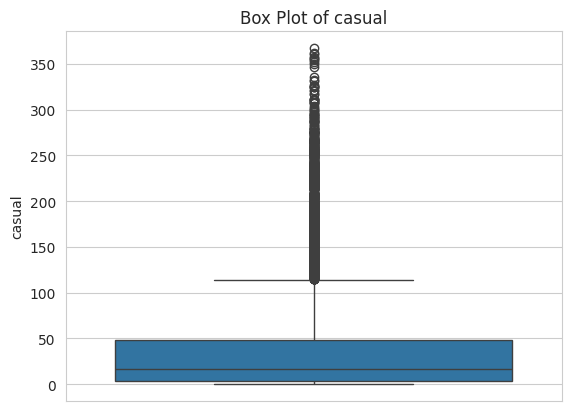

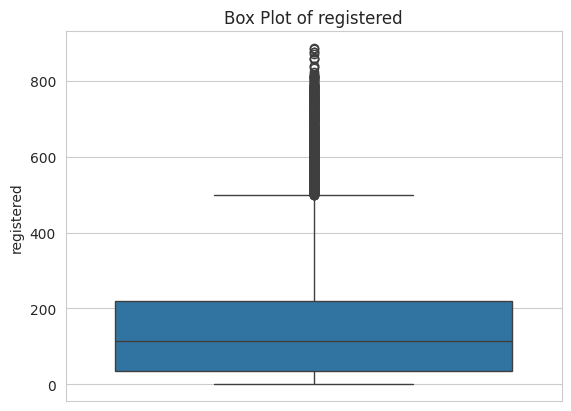

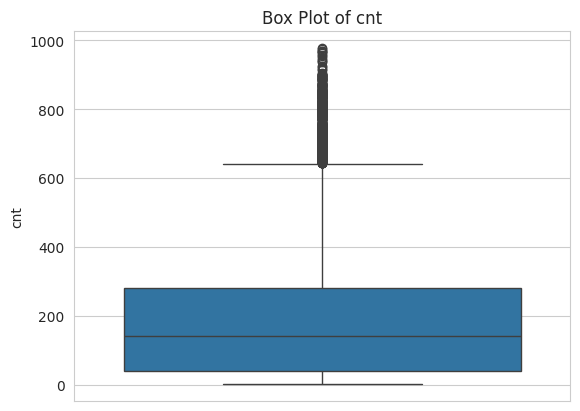

In [ ]:
for col in df.select_dtypes(include=['int','float']).columns:
    sns.boxplot(df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

In [ ]:
# Outlier Capping (excluding the target column 'cnt')
for i in df.select_dtypes(include=['int', 'float']).columns:
    if i in ['cnt', 'casual', 'registered']:
     continue

    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    IQR = q3 - q1

    lower = q1 - 1.5 * IQR
    upper = q3 + 1.5 * IQR

    df[i] = df[i].clip(lower, upper)

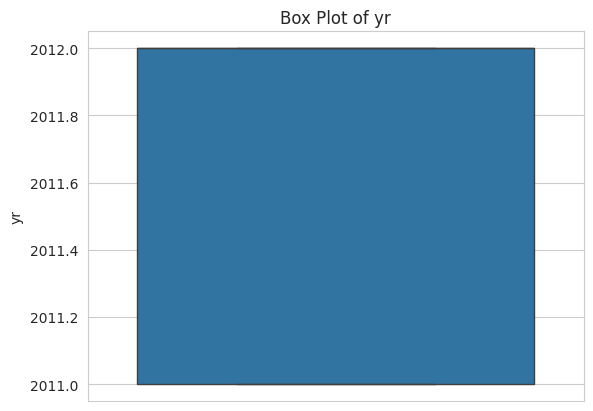

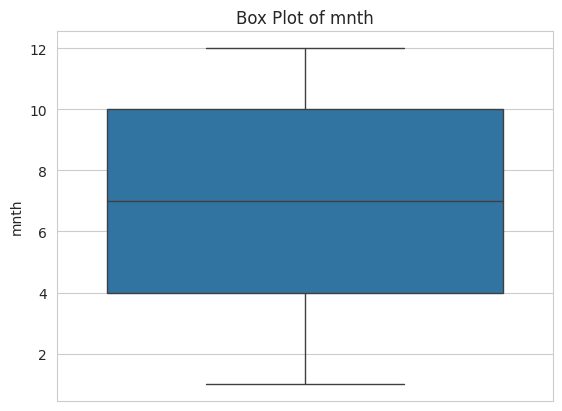

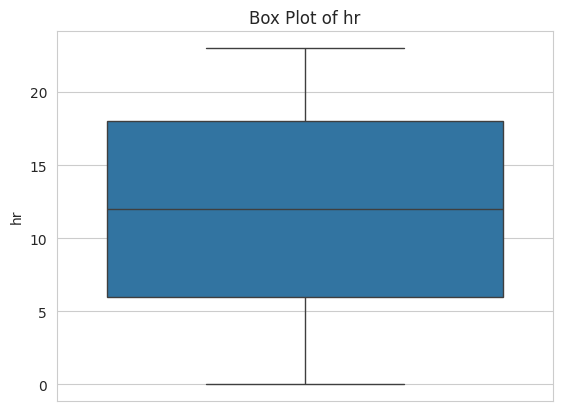

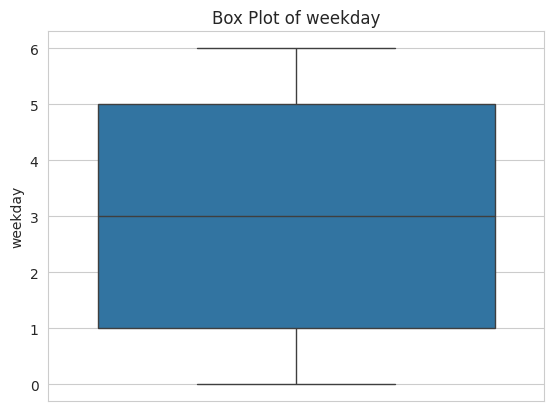

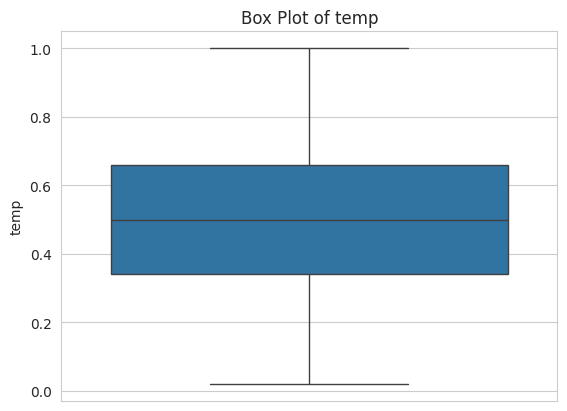

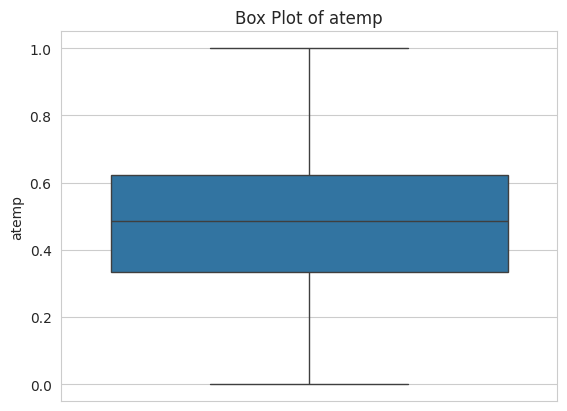

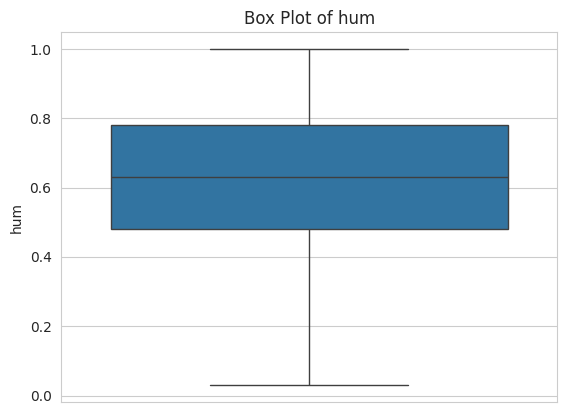

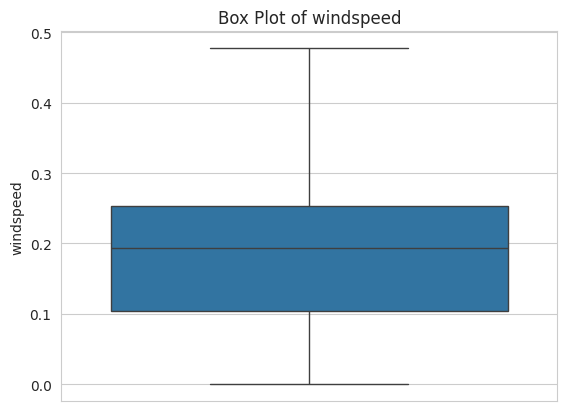

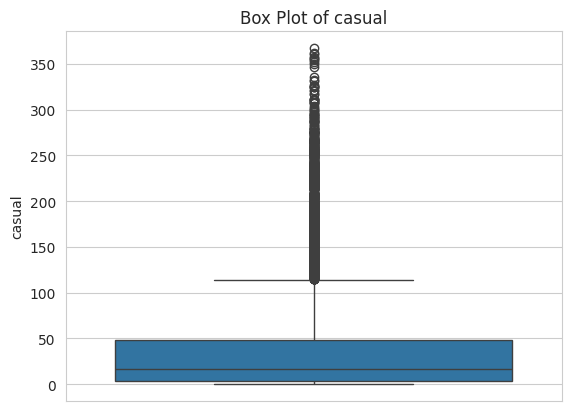

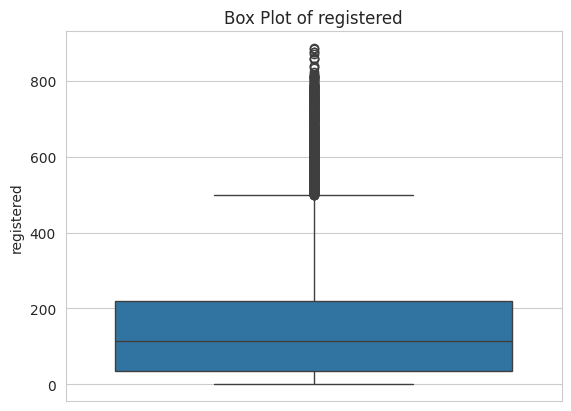

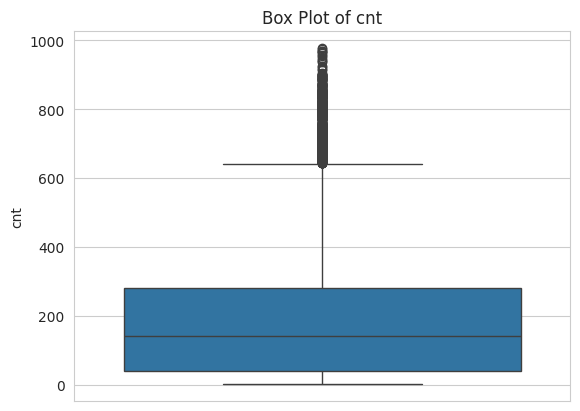

In [ ]:
for col in df.select_dtypes(include=['int','float']).columns:
    sns.boxplot(df[col])
    plt.title(f'Box Plot of {col}')
    plt.show()

## 2.data visulization

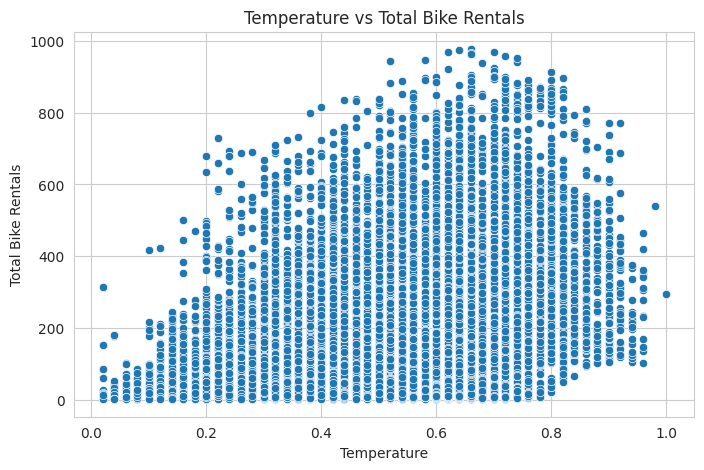

In [ ]:
#scatter plots, line plots, and bar plots to explore relationships between variables.
#Temperature vs. bike rentals
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='temp', y='cnt')
plt.title('Temperature vs Total Bike Rentals')
plt.xlabel('Temperature')
plt.ylabel('Total Bike Rentals')
plt.show()

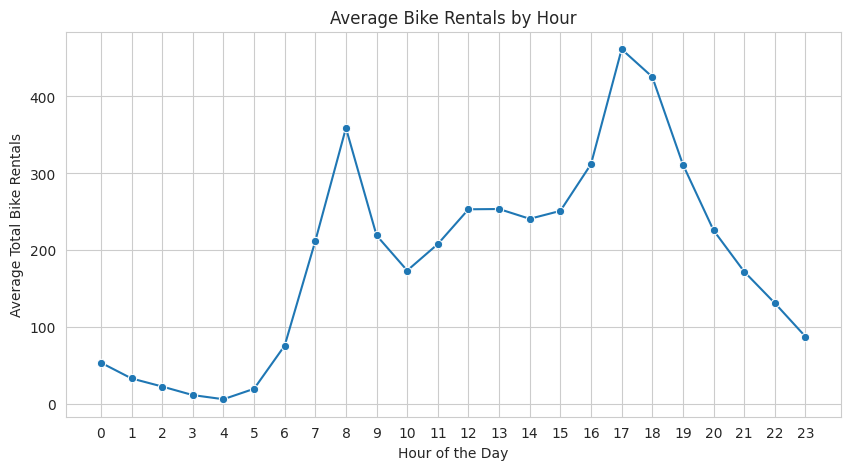

In [ ]:
#Bike rentals by hour
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='hr', y='cnt', errorbar=None, marker='o')
plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Total Bike Rentals')
plt.xticks(range(0, 24))
plt.show()

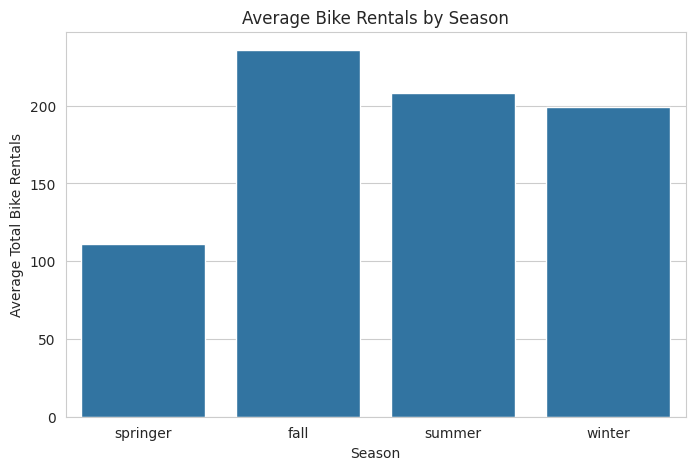

In [ ]:
#Average rentals by season
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='season', y='cnt', errorbar=None)
plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average Total Bike Rentals')
plt.show()

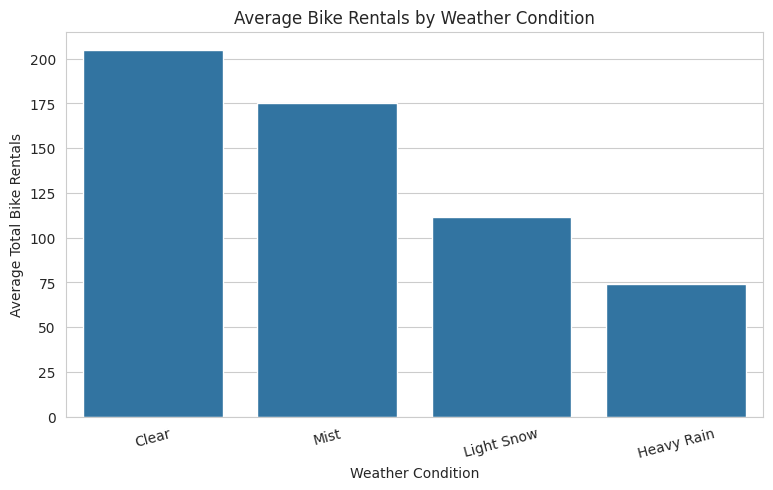

In [ ]:
#Average rentals by weather
plt.figure(figsize=(9, 5))

sns.barplot(data=df, x='weathersit', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Total Bike Rentals')

plt.xticks(rotation=15)
plt.show()

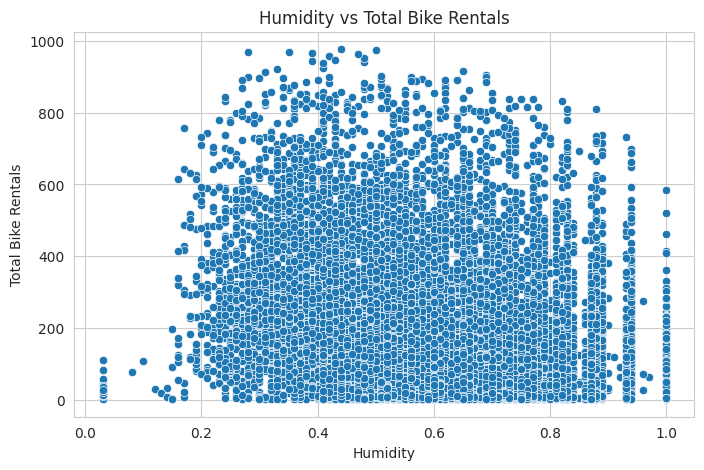

In [ ]:
#Humidity vs. bike rentals
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='hum', y='cnt')

plt.title('Humidity vs Total Bike Rentals')
plt.xlabel('Humidity')
plt.ylabel('Total Bike Rentals')

plt.show()

In [ ]:
df['dteday'] = pd.to_datetime(df['dteday'],format='%d-%m-%Y',errors='raise')

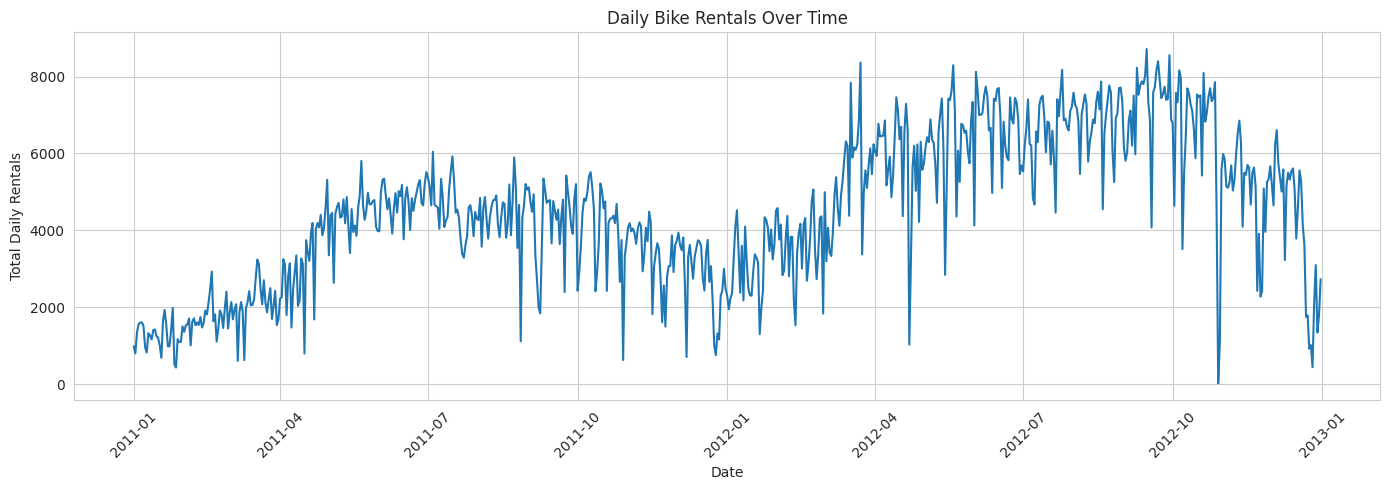

In [ ]:
#Plot bike rentals over time
daily_rentals = df.groupby('dteday')['cnt'].sum().reset_index()

plt.figure(figsize=(14, 5))

sns.lineplot(data=daily_rentals, x='dteday', y='cnt')

plt.title('Daily Bike Rentals Over Time')
plt.xlabel('Date')
plt.ylabel('Total Daily Rentals')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

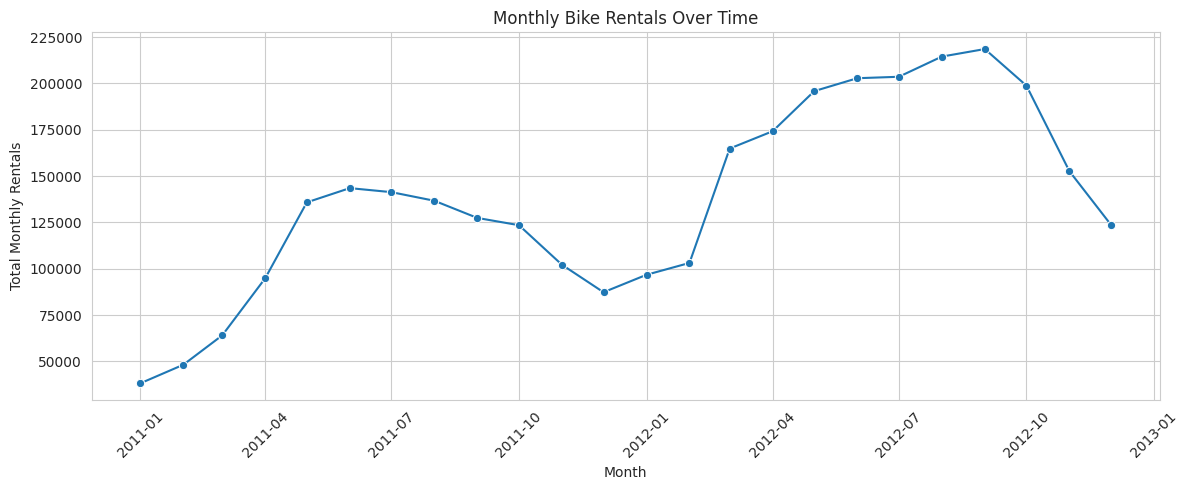

In [ ]:
#Plot monthly rental trends
monthly_rentals = (
    df.set_index('dteday')
      .resample('MS')['cnt']
      .sum()
      .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(data=monthly_rentals, x='dteday', y='cnt', marker='o')

plt.title('Monthly Bike Rentals Over Time')
plt.xlabel('Month')
plt.ylabel('Total Monthly Rentals')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

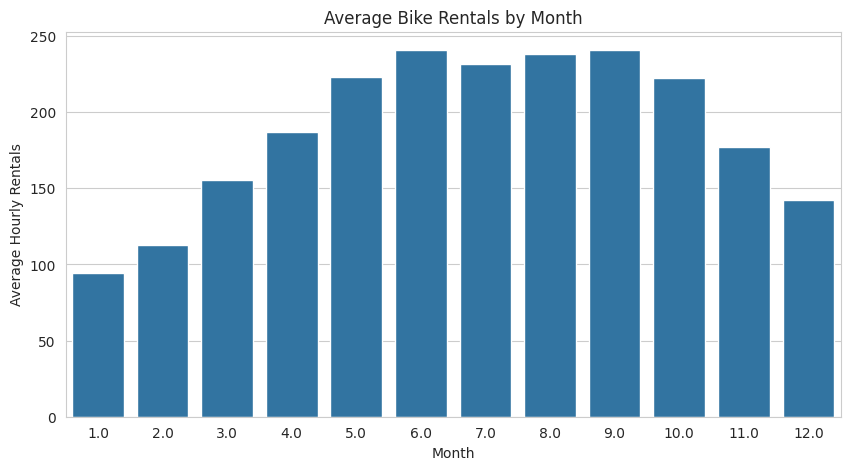

In [ ]:
#Analyze seasonality by month
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='mnth', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Month')
plt.xlabel('Month')
plt.ylabel('Average Hourly Rentals')

plt.show()

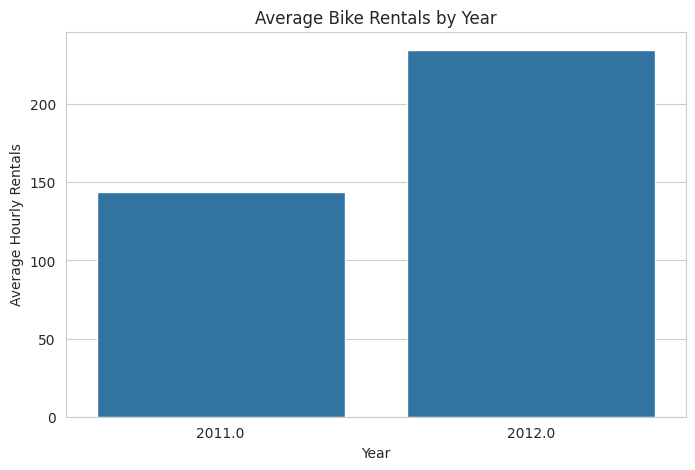

In [ ]:
#Compare rentals across years
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='yr', y='cnt', errorbar=None)

plt.title('Average Bike Rentals by Year')
plt.xlabel('Year')
plt.ylabel('Average Hourly Rentals')

plt.show()

In [ ]:
#Calculate the correlation matrix
# Select numerical columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation values
correlation_matrix

,yr,mnth,hr,weekday,temp,atemp,hum,windspeed,casual,registered,cnt
yr,1.000000,-0.010742,-0.003776,-0.004542,0.041164,0.039425,-0.083695,-0.009185,0.142711,0.253642,0.250454
mnth,-0.010742,1.000000,-0.005838,0.010484,0.202538,0.208835,0.164404,-0.133761,0.068521,0.122248,0.120658
hr,-0.003776,-0.005838,1.000000,-0.003498,0.137708,0.133940,-0.276689,0.137728,0.301200,0.374146,0.394071
weekday,-0.004542,0.010484,-0.003498,1.000000,-0.002015,-0.008678,-0.037121,0.010406,0.032700,0.021612,0.026900
temp,0.041164,0.202538,0.137708,-0.002015,1.000000,0.987010,-0.069894,-0.019952,0.459476,0.335055,0.404482
atemp,0.039425,0.208835,0.133940,-0.008678,0.987010,1.000000,-0.052018,-0.059303,0.454168,0.332480,0.400890
hum,-0.083695,0.164404,-0.276689,-0.037121,-0.069894,-0.052018,1.000000,-0.290654,-0.347347,-0.274164,-0.323200
windspeed,-0.009185,-0.133761,0.137728,0.010406,-0.019952,-0.059303,-0.290654,1.000000,0.094675,0.086653,0.098040
casual,0.142711,0.068521,0.301200,0.032700,0.459476,0.454168,-0.347347,0.094675,1.000000,0.506622,0.694570
registered,0.253642,0.122248,0.374146,0.021612,0.335055,0.332480,-0.274164,0.086653,0.506622,1.000000,0.972148


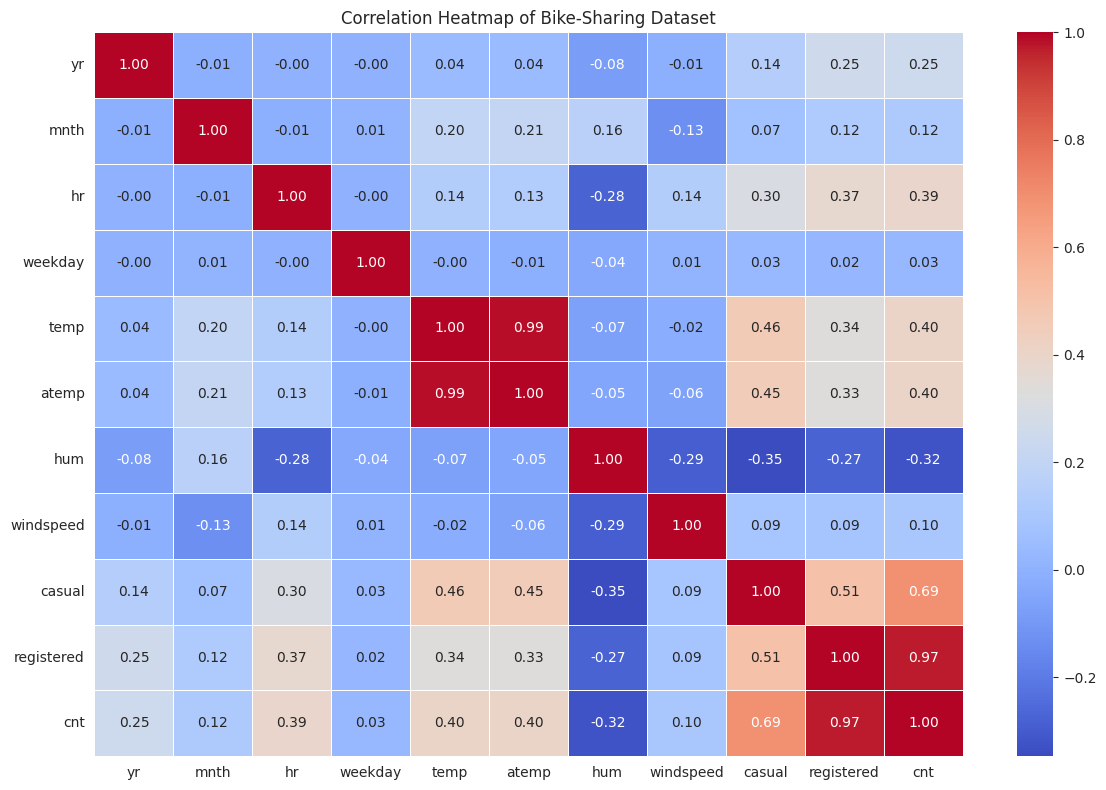

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5)

plt.title('Correlation Heatmap of Bike-Sharing Dataset')
plt.tight_layout()
plt.show()

In [ ]:
cnt_correlation = correlation_matrix['cnt'].sort_values(
    ascending=False
)

print(cnt_correlation)

cnt           1.000000
registered    0.972148
casual        0.694570
temp          0.404482
atemp         0.400890
hr            0.394071
yr            0.250454
mnth          0.120658
windspeed     0.098040
weekday       0.026900
hum          -0.323200
Name: cnt, dtype: float64


### 3.feature engineering

In [ ]:
#weekend feature
#This feature identifies whether a rental record falls on a weekend
df['is_weekend'] = df['weekday'].isin([0, 6]).astype(int)
df[['weekday', 'is_weekend']].head()

,weekday,is_weekend
0,6,1
1,6,1
2,6,1
3,6,1
4,6,1


In [ ]:
#time-of-day feature
#group the 24 hours into four periods.
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['time_period'] = df['hr'].apply(get_time_period)

df[['hr', 'time_period']].head(24)

,hr,time_period
0,0,Night
1,1,Night
2,2,Night
3,3,Night
4,4,Night
5,5,Morning
6,6,Morning
7,7,Morning
8,8,Morning
9,9,Morning


In [ ]:
#rush-hour feature
df['is_rush_hour'] = df['hr'].isin([7, 8, 9, 17, 18, 19]).astype(int)

df[['hr', 'is_rush_hour']].head(10)

,hr,is_rush_hour
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,0
7,7,1
8,8,1
9,9,1


In [ ]:
#Extract the month and year from the date
#dataset already has mnth and yr, but we can create date-derived features for consistency.
df['month_from_date'] = df['dteday'].dt.month
df['year_from_date'] = df['dteday'].dt.year
df[['dteday', 'month_from_date', 'year_from_date']].head()

,dteday,month_from_date,year_from_date
0,2011-01-01,1,2011
1,2011-01-01,1,2011
2,2011-01-01,1,2011
3,2011-01-01,1,2011
4,2011-01-01,1,2011


In [ ]:
#new features
new_features = [
    'is_weekend',
    'time_period',
    'is_rush_hour',
    'month_from_date',
    'year_from_date'
]

df[new_features].head()

,is_weekend,time_period,is_rush_hour,month_from_date,year_from_date
0,1,Night,0,1,2011
1,1,Night,0,1,2011
2,1,Night,0,1,2011
3,1,Night,0,1,2011
4,1,Night,0,1,2011


In [ ]:
#Compareing average rentals by time period
df.groupby('time_period')['cnt'].mean().sort_values(ascending=False)

,cnt
time_period,
Evening,356.201441
Afternoon,262.244719
Morning,181.520583
Night,65.687968


In [ ]:
#categorical columns
df.select_dtypes(include=['object', 'category']).dtypes

,0
season,object
holiday,object
workingday,object
weathersit,object
time_period,object


In [ ]:
categorical_columns = [
    'season',
    'holiday',
    'workingday',
    'weathersit',
    'time_period'
]

print("Column data types:")
print(df[categorical_columns].dtypes)

print("\nUnique values in each column:")
for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())

Column data types:
season         object
holiday        object
workingday     object
weathersit     object
time_period    object
dtype: object

Unique values in each column:

season:
['springer' 'fall' 'summer' 'winter']

holiday:
['No' 'Yes']

workingday:
['No work' 'Working Day']

weathersit:
['Clear' 'Mist' 'Light Snow' 'Heavy Rain']

time_period:
['Night' 'Morning' 'Afternoon' 'Evening']


In [ ]:
from sklearn.preprocessing import OneHotEncoder# Select categorical columns
# Select categorical columns
categorical_columns = [
    'season',
    'holiday',
    'workingday',
    'weathersit',
    'time_period'
]
ohe = OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)
encoded_data = ohe.fit_transform(df[categorical_columns])
# Convert encoded data into a DataFrame
encoded_df = pd.DataFrame(encoded_data,columns=ohe.get_feature_names_out(categorical_columns),index=df.index)
# Remove original categorical columns and add encoded columns
df = pd.concat([df.drop(columns=categorical_columns), encoded_df],axis=1)
df.head()

,dteday,yr,mnth,hr,weekday,temp,atemp,hum,windspeed,casual,...,season_summer,season_winter,holiday_Yes,workingday_Working Day,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist,time_period_Evening,time_period_Morning,time_period_Night
0,2011-01-01,2011.0,1.0,0,6,0.24,0.2879,0.81,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2011-01-01,2011.0,1.0,1,6,0.22,0.2727,0.80,0.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2011-01-01,2011.0,1.0,2,6,0.22,0.2727,0.63,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2011-01-01,2011.0,1.0,3,6,0.24,0.2879,0.75,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2011-01-01,2011.0,1.0,4,6,0.24,0.2879,0.75,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
df.head()

,dteday,yr,mnth,hr,weekday,temp,atemp,hum,windspeed,casual,...,season_summer,season_winter,holiday_Yes,workingday_Working Day,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist,time_period_Evening,time_period_Morning,time_period_Night
0,2011-01-01,2011.0,1.0,0,6,0.24,0.2879,0.81,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2011-01-01,2011.0,1.0,1,6,0.22,0.2727,0.80,0.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2011-01-01,2011.0,1.0,2,6,0.22,0.2727,0.63,0.0,5.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2011-01-01,2011.0,1.0,3,6,0.24,0.2879,0.75,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2011-01-01,2011.0,1.0,4,6,0.24,0.2879,0.75,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [ ]:
display(df[
    ['season_springer', 'season_summer', 'season_winter']
].head(10))

,season_springer,season_summer,season_winter
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0
5,1.0,0.0,0.0
6,1.0,0.0,0.0
7,1.0,0.0,0.0
8,1.0,0.0,0.0
9,1.0,0.0,0.0


In [ ]:
X = df.drop(columns=['cnt', 'casual', 'registered', 'dteday','year_from_date'])
y = df['cnt']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42)

In [ ]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (13903, 22)
X_test shape: (3476, 22)
y_train shape: (13903,)
y_test shape: (3476,)


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("Missing values in training data:", np.isnan(X_train_scaled).sum())
print("Missing values in testing data:", np.isnan(X_test_scaled).sum())

Training data shape: (13903, 22)
Testing data shape: (3476, 22)
Missing values in training data: 0
Missing values in testing data: 0


## 4.Model Building

In [ ]:
#LinearRegression
from sklearn.linear_model import LinearRegression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_predictions = lr_model.predict(X_test_scaled)
print("Actual values:", y_test.iloc[:10].values)
print("Predicted values:", lr_predictions[:10])

Actual values: [425  88   4 526  13  32 706  26   2  21]
Predicted values: [541.28696982 165.32767229  -5.64442603 520.40304377 -91.45949743
 -48.16711898 501.71127259 189.95228602  61.88568283  88.53613739]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("-------------------------")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression Results
-------------------------
MAE: 80.68737018886883
RMSE: 108.21227596983755
R2 Score: 0.630199129701797


In [ ]:
#DecisionTree
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

In [ ]:
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Results")
print("---------------------")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Results
---------------------
MAE: 34.2758918296893
RMSE: 58.879471347363456
R2 Score: 0.8905180131939849


In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100,random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

In [ ]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Results
---------------------
MAE: 24.514107427119292
RMSE: 41.63707783528765
R2 Score: 0.9452511059388691


In [ ]:
#GradientBoosting
from sklearn.ensemble import GradientBoostingRegressor
gb_model = GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,max_depth=3,random_state=42)
gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

In [ ]:
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R2 Score:", gb_r2)

Gradient Boosting Results
-------------------------
MAE: 40.787019366508005
RMSE: 59.64805423091317
R2 Score: 0.8876411130198166


In [ ]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        lr_mae,
        dt_mae,
        rf_mae,
        gb_mae
    ],
    'RMSE': [
        lr_rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse
    ],
    'R2 Score': [
        lr_r2,
        dt_r2,
        rf_r2,
        gb_r2
    ]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,80.687370,108.212276,0.630199
1,Decision Tree,34.275892,58.879471,0.890518
2,Random Forest,24.514107,41.637078,0.945251
3,Gradient Boosting,40.787019,59.648054,0.887641


In [ ]:
best_model = model_comparison.sort_values(
    by='R2 Score',
    ascending=False
)

print("Model Performance Ranking:")
display(best_model)

Model Performance Ranking:


,Model,MAE,RMSE,R2 Score
2,Random Forest,24.514107,41.637078,0.945251
1,Decision Tree,34.275892,58.879471,0.890518
3,Gradient Boosting,40.787019,59.648054,0.887641
0,Linear Regression,80.687370,108.212276,0.630199


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,hr,4.657338e-01
4,temp,1.165038e-01
0,yr,8.356552e-02
19,time_period_Evening,7.090582e-02
15,workingday_Working Day,5.554729e-02
9,is_rush_hour,4.116257e-02
6,hum,2.774414e-02
5,atemp,2.492400e-02
8,is_weekend,1.633901e-02
21,time_period_Night,1.540078e-02


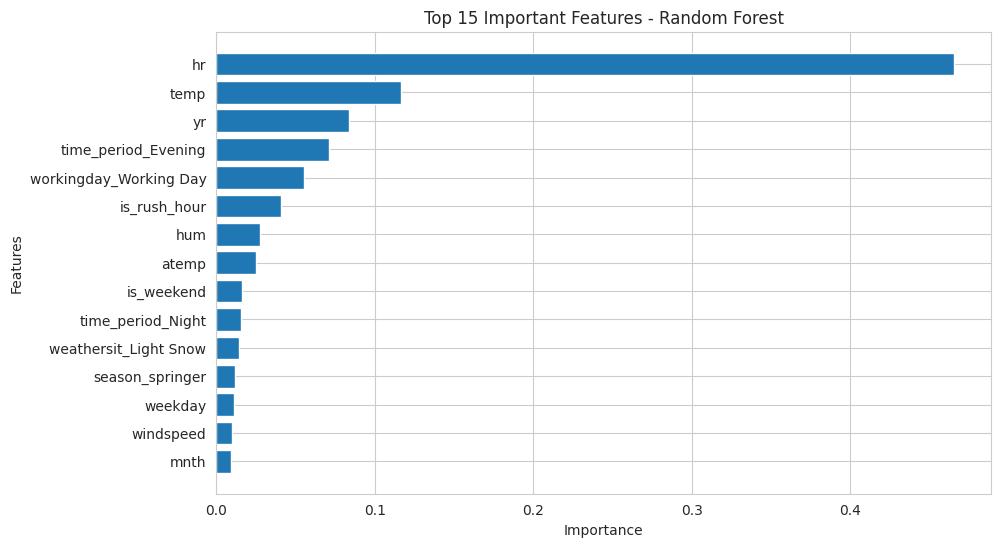

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'][:15],
    feature_importance['Importance'][:15]
)

plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Top 15 Important Features - Random Forest')
plt.gca().invert_yaxis()

plt.show()

## 5.Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30, 40],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

## It tests different combinations of model parameters and uses cross-validation to identify promising combinations.
Here's what these parameters mean:
Parameter	Purpose
n_estimators	Number of decision trees
max_depth	Maximum depth of each tree
min_samples_split	Minimum samples needed to split a node
min_samples_leaf	Minimum samples required in a leaf


n_iter=12: Tests 12 randomly selected combinations.
cv=3: Uses 3-fold cross-validation.
scoring='neg_mean_absolute_error': Selects parameters based on MAE (lower MAE is better).
n_jobs=-1: Uses available processor cores.

We use only the training data for tuning. The test data remains untouched until final evaluation.

In [ ]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_grid,
    n_iter=12,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [ ]:
rf_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


RandomizedSearchCV(cv=3, estimator=RandomForestRegressor(random_state=42),
                   n_iter=12, n_jobs=-1,
                   param_distributions={'max_depth': [None, 10, 20, 30, 40],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 200, 300]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

Parameter	Best value
n_estimators	300
max_depth	40
min_samples_split	2
min_samples_leaf	1

In [ ]:
print("Best Parameters:")
print(rf_search.best_params_)

Best Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 40}


In [ ]:
best_rf_model = rf_search.best_estimator_
best_rf_predictions = best_rf_model.predict(X_test)

In [ ]:
best_rf_mae = mean_absolute_error(y_test, best_rf_predictions)

best_rf_rmse = np.sqrt(
    mean_squared_error(y_test, best_rf_predictions)
)

best_rf_r2 = r2_score(y_test, best_rf_predictions)

print("Tuned Random Forest Results")
print("---------------------------")
print("MAE:", best_rf_mae)
print("RMSE:", best_rf_rmse)
print("R2 Score:", best_rf_r2)

Tuned Random Forest Results
---------------------------
MAE: 24.445082414333207
RMSE: 41.50606804232244
R2 Score: 0.9455950953540757


In [ ]:
comparison = pd.DataFrame({
    'Model': ['Original Random Forest', 'Tuned Random Forest'],
    'MAE': [rf_mae, best_rf_mae],
    'RMSE': [rf_rmse, best_rf_rmse],
    'R2 Score': [rf_r2, best_rf_r2]
})

display(comparison)

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,24.514107,41.637078,0.945251
1,Tuned Random Forest,24.445082,41.506068,0.945595


Comparison
Metric	Original RF	Tuned RF	Improvement
MAE	24.5141	24.4451	0.0690 lower
RMSE	41.6371	41.5061	0.1310 lower
R² Score	0.945251	0.945595	0.000344 higher

What this means:
- MAE: The tuned model's predictions are off by about 24.45 bike rentals on average.
- RMSE: Its RMSE is slightly lower, meaning it has a small improvement in prediction errors.
- R²: It explains approximately 94.56% of the variation in bike rental demand.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor

dt_param_grid = {
    'max_depth': [None, 5, 10, 15, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2']
}

dt_search = RandomizedSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_distributions=dt_param_grid,
    n_iter=12,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

dt_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


RandomizedSearchCV(cv=3, estimator=DecisionTreeRegressor(random_state=42),
                   n_iter=12, n_jobs=-1,
                   param_distributions={'max_depth': [None, 5, 10, 15, 20, 30],
                                        'max_features': [None, 'sqrt', 'log2'],
                                        'min_samples_leaf': [1, 2, 4, 8],
                                        'min_samples_split': [2, 5, 10, 20]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [ ]:
print("Best Parameters:", dt_search.best_params_)
print("Best Cross-Validation MAE:", -dt_search.best_score_)

Best Parameters: {'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 20}
Best Cross-Validation MAE: 32.85112997586137


In [ ]:
best_dt_model = dt_search.best_estimator_
dt_predictions = best_dt_model.predict(X_test)

In [ ]:
dt_mae = mean_absolute_error(y_test, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_predictions))
dt_r2 = r2_score(y_test, dt_predictions)

print("Tuned Decision Tree Results")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Tuned Decision Tree Results
MAE: 30.537264401450653
RMSE: 52.10135209161167
R2 Score: 0.9142739419699628


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb_param_grid = {
    'n_estimators': [100, 150, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

gb_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions=gb_param_grid,
    n_iter=12,
    cv=3,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


RandomizedSearchCV(cv=3, estimator=GradientBoostingRegressor(random_state=42),
                   n_iter=12, n_jobs=-1,
                   param_distributions={'learning_rate': [0.01, 0.05, 0.1, 0.2],
                                        'max_depth': [2, 3, 4, 5],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [100, 150, 200, 300]},
                   random_state=42, scoring='neg_mean_absolute_error',
                   verbose=1)

In [ ]:
print("Best Parameters:", gb_search.best_params_)
print("Best Cross-Validation MAE:", -gb_search.best_score_)

Best Parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': 5, 'learning_rate': 0.1}
Best Cross-Validation MAE: 27.425314790939215


In [ ]:
best_gb_model = gb_search.best_estimator_

gb_predictions = best_gb_model.predict(X_test)

In [ ]:
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
gb_r2 = r2_score(y_test, gb_predictions)

print("Tuned Gradient Boosting Results")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R2 Score:", gb_r2)

Tuned Gradient Boosting Results
MAE: 25.791000650687543
RMSE: 40.943582639145276
R2 Score: 0.9470596815712768


In [ ]:
tuned_comparison = pd.DataFrame({
    'Model': [
        'Tuned Random Forest',
        'Tuned Decision Tree',
        'Tuned Gradient Boosting'
    ],
    'MAE': [best_rf_mae, dt_mae, gb_mae],
    'RMSE': [best_rf_rmse, dt_rmse, gb_rmse],
    'R2 Score': [best_rf_r2, dt_r2, gb_r2]
})

display(tuned_comparison.sort_values(by='RMSE'))

,Model,MAE,RMSE,R2 Score
2,Tuned Gradient Boosting,25.791001,40.943583,0.947060
0,Tuned Random Forest,24.445082,41.506068,0.945595
1,Tuned Decision Tree,30.537264,52.101352,0.914274


In [ ]:
import joblib
final_model = best_gb_model
joblib.dump(final_model, 'best_bike_rental_model.pkl')
print("Final model saved successfully!")

Final model saved successfully!


In [ ]:
#overfitting and underfiting
# Predictions on training data
gb_train_predictions = best_gb_model.predict(X_train)

# Training metrics
train_mae = mean_absolute_error(y_train, gb_train_predictions)
train_rmse = np.sqrt(mean_squared_error(y_train, gb_train_predictions))
train_r2 = r2_score(y_train, gb_train_predictions)

# Testing metrics
test_mae = gb_mae
test_rmse = gb_rmse
test_r2 = gb_r2

# Display comparison
overfitting_check = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'R2 Score'],
    'Training': [train_mae, train_rmse, train_r2],
    'Testing': [test_mae, test_rmse, test_r2]
})

display(overfitting_check)

,Metric,Training,Testing
0,MAE,23.187566,25.791001
1,RMSE,35.801376,40.943583
2,R2 Score,0.961396,0.947060


## The tuned Gradient Boosting Regressor was evaluated using training and testing datasets. The model achieved an R² score of 0.9614 on training data and 0.9471 on testing data. The small difference between these scores indicates that the model generalizes well to unseen data, with no strong evidence of severe overfitting.

In [ ]:
# Store the tuned models
models = {
    'Tuned Decision Tree': best_dt_model,
    'Tuned Random Forest': best_rf_model,
    'Tuned Gradient Boosting': best_gb_model
}

results = []

for name, model in models.items():

    # Training predictions
    train_predictions = model.predict(X_train)

    # Testing predictions
    test_predictions = model.predict(X_test)

    # Calculate metrics
    results.append({
        'Model': name,
        'Train MAE': mean_absolute_error(y_train, train_predictions),
        'Test MAE': mean_absolute_error(y_test, test_predictions),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_predictions)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_predictions)),
        'Train R2': r2_score(y_train, train_predictions),
        'Test R2': r2_score(y_test, test_predictions)
    })

model_overfitting_comparison = pd.DataFrame(results)

display(model_overfitting_comparison.round(4))

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Tuned Decision Tree,21.4545,30.5373,35.6465,52.1014,0.9617,0.9143
1,Tuned Random Forest,9.3365,24.4451,15.6198,41.5061,0.9927,0.9456
2,Tuned Gradient Boosting,23.1876,25.7910,35.8014,40.9436,0.9614,0.9471


## 6.Model Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Generate predictions from each model
model_predictions = {
    'Linear Regression': lr_model.predict(X_test_scaled),
    'Tuned Decision Tree': best_dt_model.predict(X_test),
    'Tuned Random Forest': best_rf_model.predict(X_test),
    'Tuned Gradient Boosting': best_gb_model.predict(X_test)
}

# Calculate evaluation metrics
evaluation_results = []

for name, predictions in model_predictions.items():
    evaluation_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'MSE': mean_squared_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

model_evaluation = pd.DataFrame(evaluation_results)

display(model_evaluation.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,80.6874,11709.8967,108.2123,0.6302
1,Tuned Decision Tree,30.5373,2714.5509,52.1014,0.9143
2,Tuned Random Forest,24.4451,1722.7537,41.5061,0.9456
3,Tuned Gradient Boosting,25.7910,1676.3770,40.9436,0.9471


In [ ]:
# Display the features expected by the trained model
print("Number of input features:", len(best_gb_model.feature_names_in_))
print("\nFeatures required by the model:")
for feature in best_gb_model.feature_names_in_:
    print(feature)

Number of input features: 22

Features required by the model:
yr
mnth
hr
weekday
temp
atemp
hum
windspeed
is_weekend
is_rush_hour
month_from_date
season_springer
season_summer
season_winter
holiday_Yes
workingday_Working Day
weathersit_Heavy Rain
weathersit_Light Snow
weathersit_Mist
time_period_Evening
time_period_Morning
time_period_Night
